In [ ]:
import os, sys
cur_directory = os.getcwd()
save_directory = os.path.join(cur_directory, 'saved')

project_folder = ...
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [25]:
import numpy as np
from numpy import linalg as la
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle
import random
from scipy.stats import ortho_group
from plot_preferences import *

blues = mpl.colormaps["Blues"]
greens = mpl.colormaps["Greens"]
greys = mpl.colormaps["Greys"]

In [ ]:
from matplotlib.colors import LinearSegmentedColormap

c1 = np.array([240, 245, 255]) / 255
c2 = np.array([6, 6, 125]) / 255

# Create a custom colormap
blues_custom = LinearSegmentedColormap.from_list("blues_custom", [c1, c2])

In [27]:
K = 50
N = 93
V_width = 7
V_E_buffer = 0
E_width = 1
setup = (V_width, V_E_buffer, E_width)
stim = "opticflow"
bank_directory = os.path.join(project_folder, 'analyses', 'basis meta neuron bank', 'saved', stim)

## Meta neuron modes

In [28]:
def filename(v, b, e, K):
    return f'({v},{b},{e}) K={K}.dat'

load_path = os.path.join(bank_directory, filename(*setup, K))
with open(load_path, 'rb') as f:
    bank_data = pickle.load(f)
basis_vectors = bank_data["basis_vectors"]
raw_mn_array = bank_data["raw_mn_array"]
meta_neurons = bank_data["meta_neurons"]
N_training_repeats = len(raw_mn_array)

modes = []
for i in range(K):
    # modes.append(basis_vectors[:,i].reshape((V_width, N)).T)
    modes.append(basis_vectors[:,i])

Lam = basis_vectors.T

In [30]:
bank_data["critic_params"]

{'hidden_dim': 32, 'embed_dim': 100, 'layers': 2, 'activation': 'tanh'}

In [6]:
raw_mn_array[0].shape

(651, 50)

In [7]:
N_training_repeats = len(raw_mn_array)
N_subsamples = 5
s = random.choices(np.arange(N_training_repeats), k=N_subsamples)
mn_weights_combined = np.concatenate(raw_mn_array[s], axis=1)

In [8]:
mn_weights_combined.shape

(651, 250)

## Do DMD

In [9]:
data_path = os.path.join(project_folder, 'data', 'nat_scenes_data')
E = ds.DataNatScenes(data_path, mov_ind=4)
print(f'current stimulus is {E.movname}')
mov_ind = E.mov_ind

# Shuffle trials
rand_perm = np.random.permutation(np.arange(E.N_trials))
trial_shuffled_data = E.data[rand_perm]
D = ds.DataTrialed(trial_shuffled_data)

# View total activity
tot_activity_E = np.array([np.sum(d.X) for d in E.data])
tot_activity_D = np.array([np.sum(d.X) for d in D.data])

# plt.plot(tot_activity_E)
# plt.plot(tot_activity_D)

current stimulus is opticflow


In [10]:
# Adding in error analysis
def dmd(X, tau=1, mean_center=True):
    if mean_center:
        X1 = X[:,:-tau] - np.mean(X[:,:-tau], axis=1, keepdims=True)
        X2 = X[:,tau:] - np.mean(X[:,tau:], axis=1, keepdims=True)
    else:
        X1 = X[:,:-tau]
        X2 = X[:,tau:]

    U = X2 @ X1.T @ la.inv(X1 @ X1.T)
    lam, V = la.eig(U)
    sort_modes = np.argsort(-np.abs(lam))
    lam = lam[sort_modes]
    V = V[:,sort_modes]
    return lam, V, U

def dmd_err(X, U, mean_center=True):
    if mean_center:
        X1 = X[:,:-tau] - np.mean(X[:,:-tau], axis=1, keepdims=True)
        X2 = X[:,tau:] - np.mean(X[:,tau:], axis=1, keepdims=True)
    else:
        X1 = X[:,:-tau]
        X2 = X[:,tau:]

    n = X1.shape[1]
    X2_pred = U @ X1
    X2_err = np.sum((X2 - X2_pred)**2, axis=1) / (n - 2)
    X1_err = np.sum(X1**2, axis=1)
    U_err = X2_err[:,None] / X1_err[None,:]
    return U_err
    

In [11]:
tau = E_width + V_E_buffer
tde = V_width - 1

# DMD
D.reset()
D.trim(20)
D.tde(tde)
N_tde = D.N
lam, V, U = dmd(D.X, tau, mean_center=False)
U_err = dmd_err(D.X, U, mean_center=False)

# DMD on shuffled data
D.reset()
D.trim(20)
# D.shuffle_time()
D.shuffle_time_and_trial()
D.tde(tde)
N_tde = D.N
lam_sh, V_sh, U_sh = dmd(D.X, tau, mean_center=False)
U_sh_err = dmd_err(D.X, U_sh, mean_center=False)

In [12]:
def subsample_Lam(N_subsamples):
    N_training_repeats = len(raw_mn_array)
    s = random.choices(np.arange(N_training_repeats), k=N_subsamples)
    mn_weights_combined = np.concatenate(raw_mn_array[s], axis=1)

    # normalize filters
    A = mn_weights_combined / np.sqrt(np.sum(mn_weights_combined**2, axis=0, keepdims=True))

    # align and sort using PCA
    lam, basis_vectors = als.pca(A)
    return basis_vectors.T

In [13]:
dt = 1/60.
def lam_to_tau(lam):
    t = - dt / np.log(lam)
    return t

In [14]:
Lam = basis_vectors.T
Lam_rand = ortho_group.rvs(N_tde)

Q = np.real(Lam @ U @ Lam.T)
Q_diag = np.diag(Q)
Q_sh = np.real(Lam @ U_sh @ Lam.T)
Q_sh_diag = np.diag(Q_sh)

In [15]:
tau = lam_to_tau(Q_diag)
tau_sh = lam_to_tau(Q_sh_diag)

/var/folders/b8/k5811h914nsdmp3chwqpyd3w0000gn/T/ipykernel_62889/94559386.py:3: RuntimeWarning: invalid value encountered in log
  t = - dt / np.log(lam)


### Compute uncertainty due to features

In [16]:
N_subsamples = 500
N_trials = 100

Lam_sub_list = []
Q_sub_diag_list = []
Q_sh_sub_diag_list = []
for n in tqdm(range(N_trials)):
    L = subsample_Lam(N_subsamples)
    Lam_sub_list.append(L)
    Q_sub_diag_list.append(np.diag(L @ U @ L.T))
    Q_sh_sub_diag_list.append(np.diag(L @ U_sh @ L.T))

100%|██████████| 100/100 [02:42<00:00,  1.63s/it]


In [17]:
Q_sub_diag = np.array(Q_sub_diag_list).T
Q_sh_sub_diag = np.array(Q_sh_sub_diag_list).T 
tau_sub = lam_to_tau(Q_sub_diag)
tau_sh_sub = lam_to_tau(Q_sh_sub_diag)

Q_sub_diag_err = np.sqrt(np.var(Q_sub_diag, axis=-1))
tau_sub_err = np.sqrt(np.var(tau_sub, axis=-1))
Q_sh_sub_diag_err = np.sqrt(np.var(Q_sh_sub_diag, axis=-1))
tau_sh_sub_err = np.sqrt(np.var(tau_sh_sub, axis=-1))

/var/folders/b8/k5811h914nsdmp3chwqpyd3w0000gn/T/ipykernel_62889/94559386.py:3: RuntimeWarning: invalid value encountered in log
  t = - dt / np.log(lam)


### Compute uncertainty due to DMD

In [18]:
Q_dmd_err = Lam**2 @ U_err @ Lam.T**2
Q_sh_dmd_err = Lam**2 @ U_sh_err @ Lam.T**2
Q_dmd_err_diag = np.sqrt(np.diag(Q_dmd_err))
Q_sh_dmd_err_diag = np.sqrt(np.diag(Q_sh_dmd_err))

def dtau_dlam(lam):
    return dt / lam / np.log(lam)**2

tau_dmd_err = np.sqrt(dtau_dlam(Q_diag)**2 * Q_dmd_err_diag**2)
tau_sh_dmd_err = np.sqrt(dtau_dlam(Q_sh_diag)**2 * Q_sh_dmd_err_diag**2)


/var/folders/b8/k5811h914nsdmp3chwqpyd3w0000gn/T/ipykernel_62889/381095984.py:7: RuntimeWarning: invalid value encountered in log
  return dt / lam / np.log(lam)**2


### Add errors

In [19]:
Q_diag_err = np.sqrt(Q_sub_diag_err**2 + Q_dmd_err_diag**2)
Q_sh_diag_err = np.sqrt(Q_sh_sub_diag_err**2 + Q_sh_dmd_err_diag**2)
tau_err = np.sqrt(tau_sub_err**2 + tau_dmd_err**2)
tau_sh_err = np.sqrt(tau_sh_sub_err**2 + tau_sh_dmd_err**2)

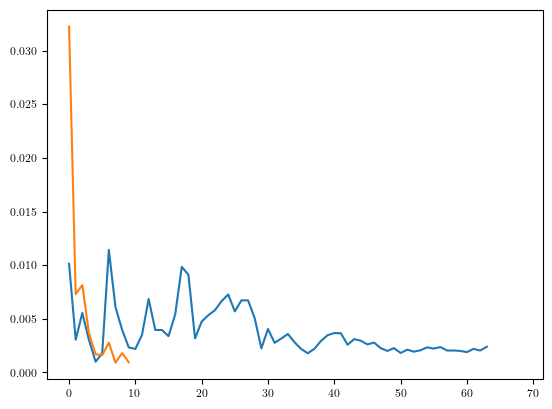

In [20]:
# plt.plot(tau_err)
# plt.plot(tau_sh_err)
plt.plot(tau_sub_err)
plt.plot(tau_dmd_err[:10])

### Plots

In [21]:
ms = 3
lw = 1

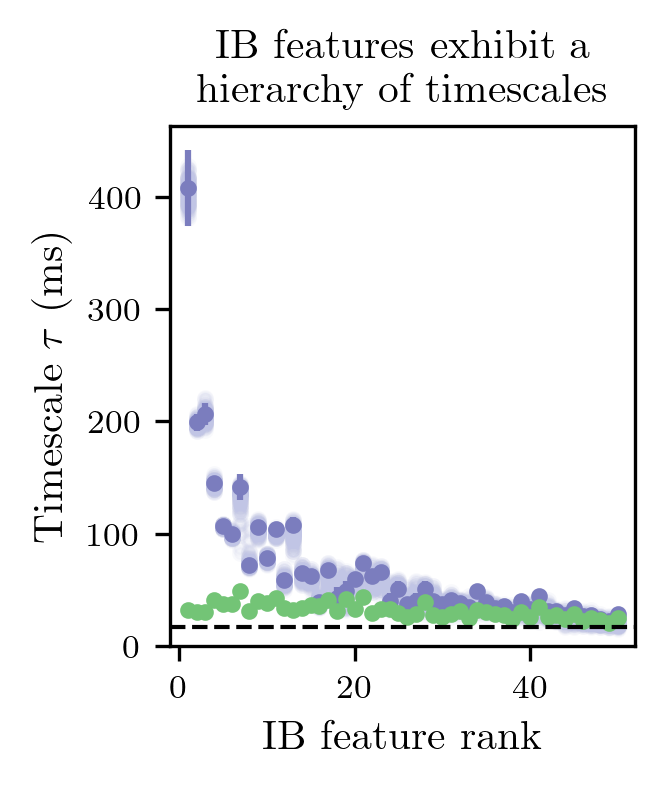

In [22]:
fig, ax = plt.subplots(figsize=[2, 2.25], dpi=300)

Nx = K
units = 1000
x = np.arange(Nx) + 1

# plt.semilogy()
plt.plot(x, tau_sub[:Nx] * units, 'o', color=blues_custom(0.2,0.1), markersize=ms);
plt.errorbar(x, tau[:Nx] * units, yerr=tau_err[:Nx] * units, marker='o', linestyle='',color=blues_custom(0.5), markersize=ms)
plt.errorbar(x, tau_sh[:Nx] * units, yerr=tau_sh_err[:Nx] * units, marker='o', linestyle='', color=greens(0.5), markersize=ms)


plt.axhline(dt * units, color=greys(0.99), linestyle='--', linewidth=lw, zorder=3)
plt.xlim(-1,x[-1] + 2)
plt.ylim(0)
# plt.ylim(10)
plt.xlabel('IB feature rank')
plt.ylabel('Timescale $\\tau$ (ms)')
plt.title('IB features exhibit a\n hierarchy of timescales')
plt.savefig('./plots/meta neuron timescales', dpi=3000)

Text(0, 0.5, '$\\Lambda_a \\hat{U} \\Lambda_a^T$')

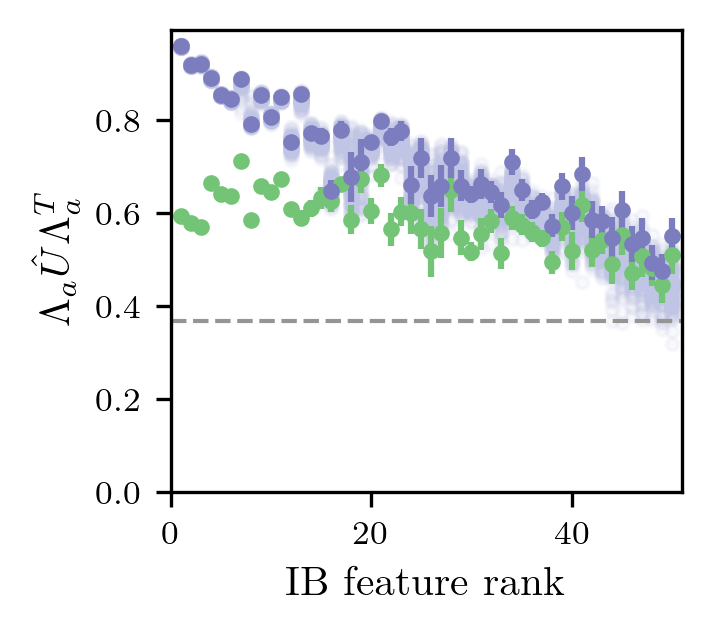

In [23]:
fig, ax = plt.subplots(figsize=[2.2, 2], dpi=300)


Nx = 50
x = np.arange(Nx) + 1

plt.plot(x, Q_sub_diag[:Nx], 'o', color=blues_custom(0.2,0.1), markersize=ms);
plt.errorbar(x, Q_sh_diag[:Nx], yerr=Q_sh_diag_err[:Nx], marker='o', linestyle='', color=greens(0.5), markersize=ms)
plt.errorbar(x, Q_diag[:Nx], yerr=Q_diag_err[:Nx], marker='o', linestyle='',color=blues_custom(0.5), markersize=ms)
plt.axhline(np.exp(-1), color=greys(128), linestyle='--', linewidth=lw)

# plt.plot(x, Q_sub_diag[:Nx], 'o', color=blues(100,0.1));
# plt.errorbar(x, Q_sh_diag[:Nx], yerr=Q_sh_diag_err[:Nx], marker='o', linestyle='', color=greens(100))
# plt.errorbar(x, Q_diag[:Nx], yerr=Q_diag_err[:Nx], marker='o', linestyle='',color=blues(255))


plt.xlim(0,x[-1]+1)
plt.ylim(0)
plt.xlabel('IB feature rank')
plt.ylabel(r'$\Lambda_a \hat{U} \Lambda_a^T$')